
#**Practical Assignment 4: Classification Models**

**Name:** Arya M. Bhat

**Div:** A  **Batch**: A1

**Roll no:** 10

**PRN:** 202401040044


## **1. Problem Statement**

The objective of this assignment is to develop and evaluate multiple supervised machine learning classification models to predict whether a mushroom is edible or poisonous based on its physical characteristics.

Four classification algorithms are implemented on the same dataset. Their performance is compared using standard evaluation metrics to determine their effectiveness, reliability and suitability for different classification problems.

## **2. Objectives**

1. To understand the working principles of SVM, Decision Tree, KNN and Naïve Bayes.
2. To perform exploratory data analysis on the Mushroom Classification Dataset.
3. To preprocess categorical data and handle missing values.
4. To implement four classification algorithms using Python and Scikit-learn.
5. To optimize model parameters using cross-validation.
6. To evaluate models using accuracy, precision, recall, F1-score and log loss.
7. To visualize and compare the performance of all four models.
8. To identify the advantages, **limitations** and practical applications of each algorithm.

## **3. Dataset Description**

**Dataset Name:** Mushroom Classification Dataset

**Dataset Source:** Kaggle – Mushroom Classification

**Dataset Link:** https://www.kaggle.com/datasets/uciml/mushroom-classification

The dataset contains descriptions of mushrooms belonging to two categories: edible and poisonous.

### **Dataset Characteristics**

- Total observations: 8,124
- Total columns: 23
- Input features: 22
- Target variable: class
- Classification type: Binary Classification
- Feature type: Categorical

### **Target Variable**

The target column is `class`.

- `e` represents Edible mushrooms.
- `p` represents Poisonous mushrooms.

### **Important Features**

Some important features include:

- cap-shape
- cap-surface
- cap-color
- bruises
- odor
- gill-attachment
- gill-spacing
- gill-size
- gill-color
- stalk-root
- ring-type
- spore-print-color
- population
- habitat

These features describe the physical characteristics of mushrooms and are used to predict their classification.

In [1]:

# ==========================================
# IMPORT REQUIRED LIBRARIES
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings

warnings.filterwarnings('ignore')

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Machine Learning algorithms
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import MultinomialNB

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    confusion_matrix,
    classification_report
)

# Additional utility
from sklearn.base import clone

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

# ==========================================
#  UPLOAD DATASET
# ==========================================

from google.colab import files

uploaded = files.upload()

# Identify the uploaded CSV file
file_name = next(
    (name for name in uploaded if name.lower().endswith('.csv')),
    None
)

if file_name is None:
    raise ValueError("Please upload a CSV file.")

# Read dataset
df = pd.read_csv(file_name)

print("Dataset uploaded successfully!")
print("File name:", file_name)


Saving mushrooms.csv to mushrooms.csv
Dataset uploaded successfully!
File name: mushrooms.csv


In [3]:

# ==========================================
#  DISPLAY DATASET
# ==========================================

print("First 5 records:")
display(df.head())

print("\nLast 5 records:")
display(df.tail())

print("\nDataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())


First 5 records:


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g



Last 5 records:


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
8119,e,k,s,n,f,n,a,c,b,y,...,s,o,o,p,o,o,p,b,c,l
8120,e,x,s,n,f,n,a,c,b,y,...,s,o,o,p,n,o,p,b,v,l
8121,e,f,s,n,f,n,a,c,b,n,...,s,o,o,p,o,o,p,b,c,l
8122,p,k,y,n,f,y,f,c,n,b,...,k,w,w,p,w,o,e,w,v,l
8123,e,x,s,n,f,n,a,c,b,y,...,s,o,o,p,o,o,p,o,c,l



Dataset dimensions: (8124, 23)

Column names:
['class', 'cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor', 'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color', 'stalk-shape', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring', 'stalk-color-above-ring', 'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number', 'ring-type', 'spore-print-color', 'population', 'habitat']


In [4]:

# ==========================================
#  DATASET INFORMATION
# ==========================================

print("Dataset Information:")
print("-" * 50)

df.info()

print("\nStatistical Summary:")
display(df.describe(include='all'))

print("\nNumber of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])


Dataset Information:
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   class                     8124 non-null   object
 1   cap-shape                 8124 non-null   object
 2   cap-surface               8124 non-null   object
 3   cap-color                 8124 non-null   object
 4   bruises                   8124 non-null   object
 5   odor                      8124 non-null   object
 6   gill-attachment           8124 non-null   object
 7   gill-spacing              8124 non-null   object
 8   gill-size                 8124 non-null   object
 9   gill-color                8124 non-null   object
 10  stalk-shape               8124 non-null   object
 11  stalk-root                8124 non-null   object
 12  stalk-surface-above-ring  8124 non-null   object
 13  stalk-

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
count,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,...,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124
unique,2,6,4,10,2,9,2,2,2,12,...,4,9,9,1,4,3,5,9,6,7
top,e,x,y,n,f,n,f,c,b,b,...,s,w,w,p,w,o,p,w,v,d
freq,4208,3656,3244,2284,4748,3528,7914,6812,5612,1728,...,4936,4464,4384,8124,7924,7488,3968,2388,4040,3148



Number of Rows: 8124
Number of Columns: 23


In [5]:

# ==========================================
# CHECK MISSING VALUES
# ==========================================

# Replace unknown '?' values with NaN
df.replace('?', np.nan, inplace=True)

print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:",
      df.isnull().sum().sum())

print("\nPercentage of missing values:")
print((df.isnull().mean() * 100).round(2))


Missing values in each column:
class                          0
cap-shape                      0
cap-surface                    0
cap-color                      0
bruises                        0
odor                           0
gill-attachment                0
gill-spacing                   0
gill-size                      0
gill-color                     0
stalk-shape                    0
stalk-root                  2480
stalk-surface-above-ring       0
stalk-surface-below-ring       0
stalk-color-above-ring         0
stalk-color-below-ring         0
veil-type                      0
veil-color                     0
ring-number                    0
ring-type                      0
spore-print-color              0
population                     0
habitat                        0
dtype: int64

Total missing values: 2480

Percentage of missing values:
class                        0.00
cap-shape                    0.00
cap-surface                  0.00
cap-color                    0.00
br

Class Distribution:
class
e    4208
p    3916
Name: count, dtype: int64


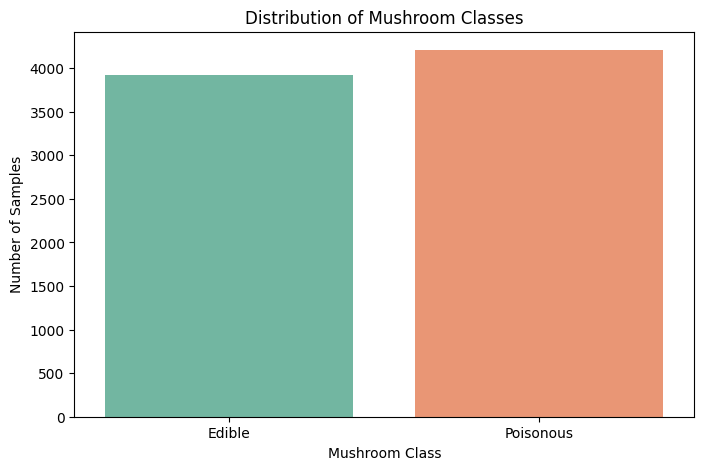

In [6]:

# ==========================================
#  CLASS DISTRIBUTION
# ==========================================

class_counts = df['class'].value_counts()

print("Class Distribution:")
print(class_counts)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='class',
    hue='class',
    palette='Set2',
    legend=False
)

plt.title("Distribution of Mushroom Classes")
plt.xlabel("Mushroom Class")
plt.ylabel("Number of Samples")
plt.xticks([0, 1], ['Edible', 'Poisonous'])

plt.show()


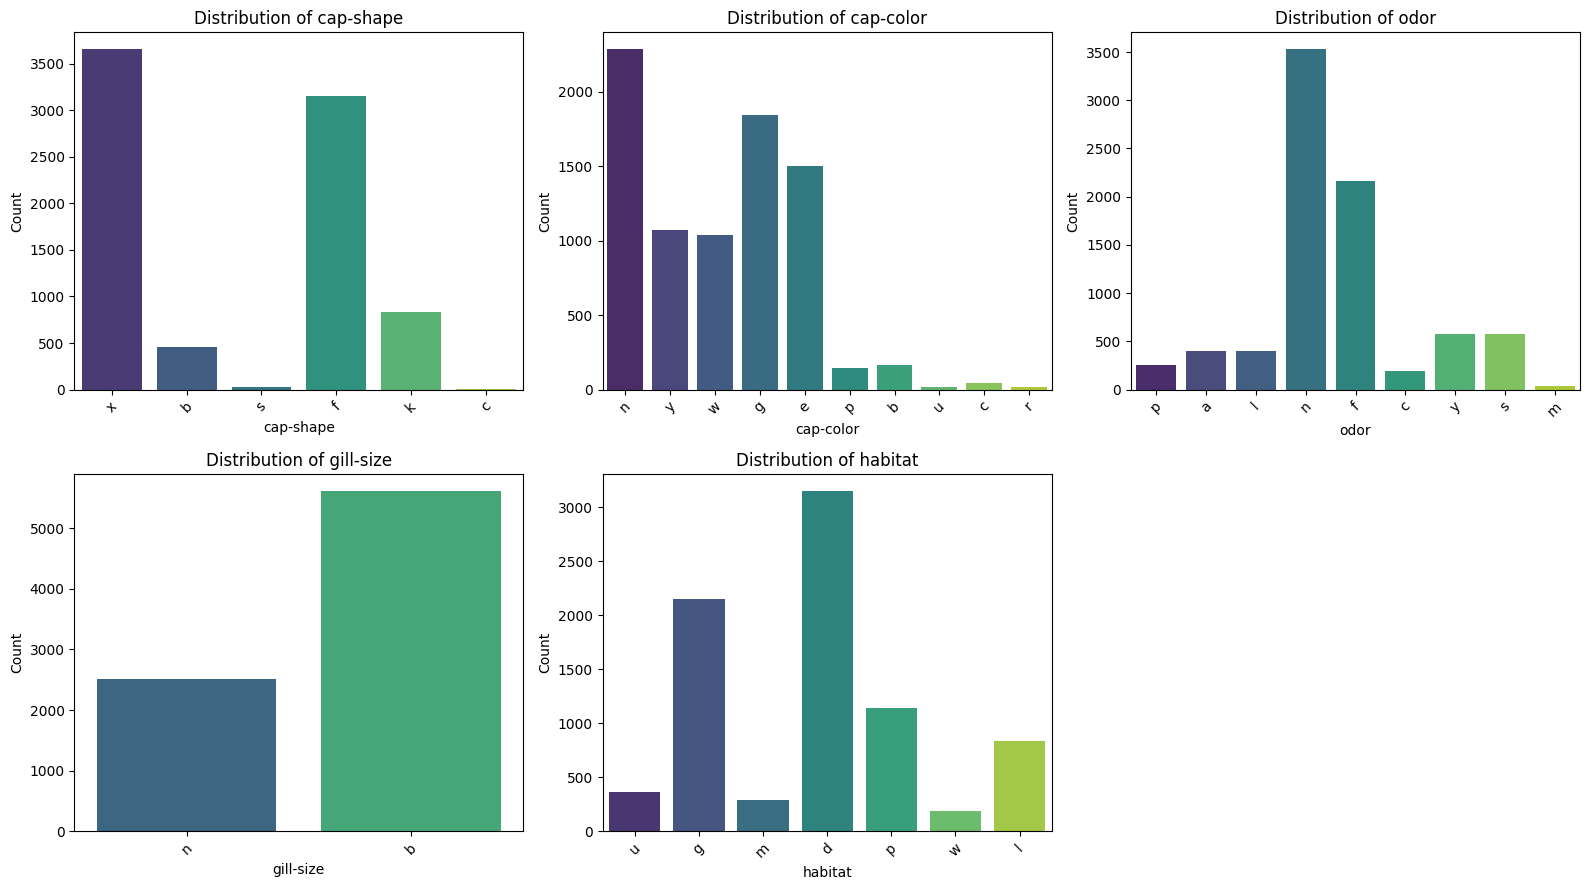

In [7]:

# ==========================================
#  FEATURE DISTRIBUTION
# ==========================================

important_features = [
    'cap-shape',
    'cap-color',
    'odor',
    'gill-size',
    'habitat'
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, feature in enumerate(important_features):

    sns.countplot(
        data=df,
        x=feature,
        hue=feature,
        palette='viridis',
        legend=False,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {feature}")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Count")
    axes[i].tick_params(axis='x', rotation=45)

axes[-1].axis('off')

plt.tight_layout()
plt.show()


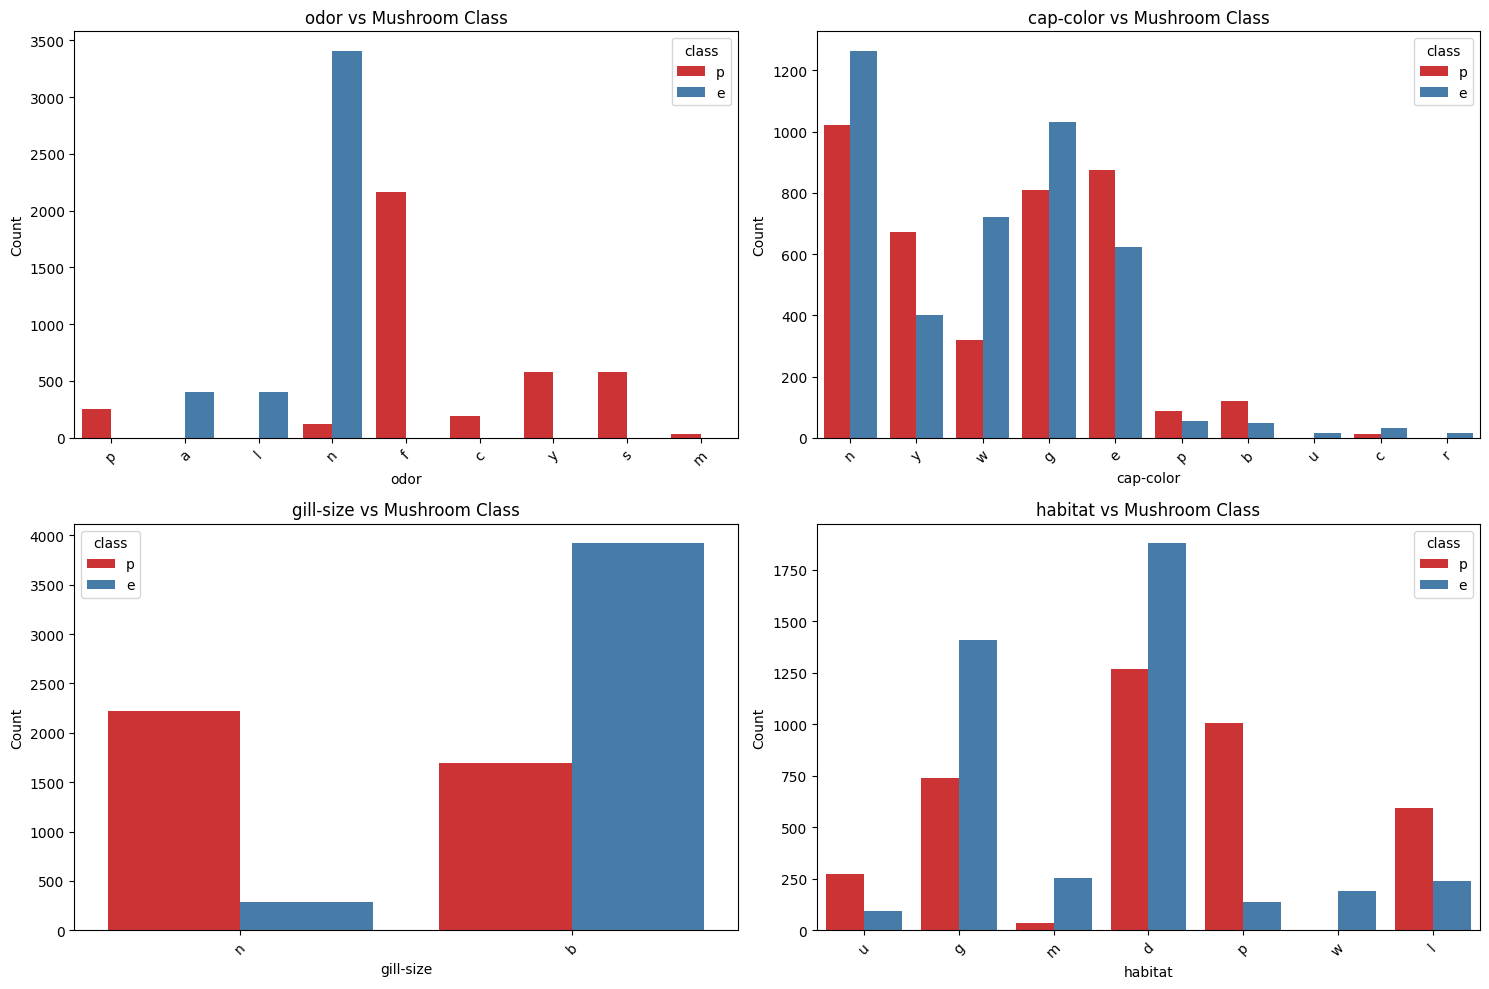

In [8]:

# ==========================================
#  FEATURE VS TARGET ANALYSIS
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

features = [
    'odor',
    'cap-color',
    'gill-size',
    'habitat'
]

for ax, feature in zip(axes.flatten(), features):

    sns.countplot(
        data=df,
        x=feature,
        hue='class',
        palette='Set1',
        ax=ax
    )

    ax.set_title(f"{feature} vs Mushroom Class")
    ax.set_xlabel(feature)
    ax.set_ylabel("Count")
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


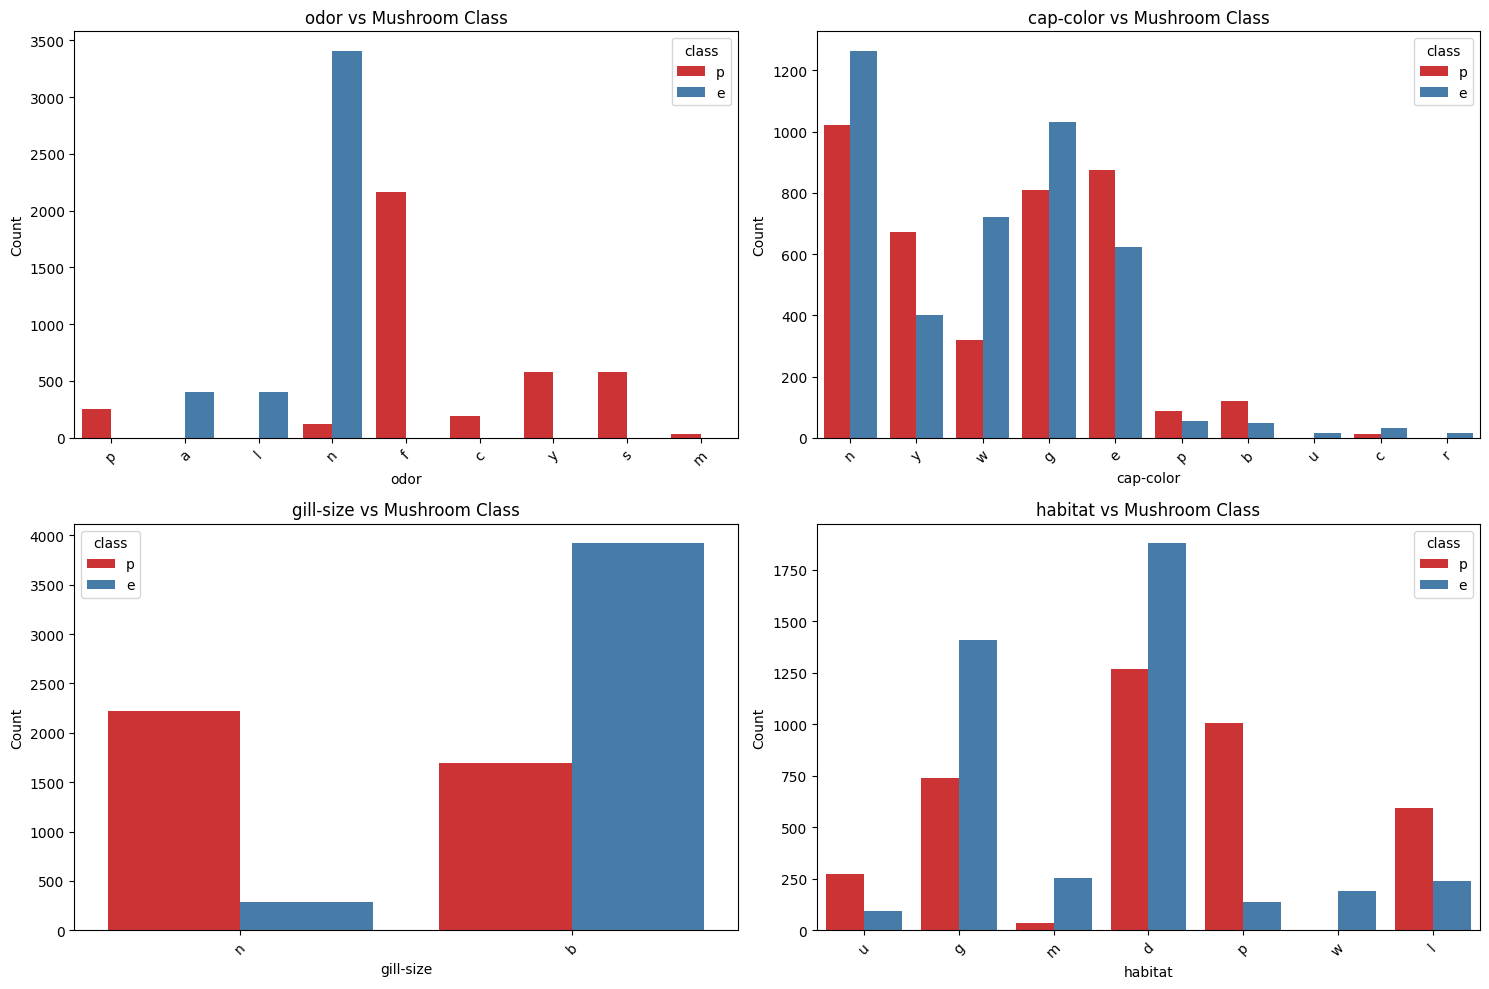

In [9]:

# ==========================================
# FEATURE VS TARGET ANALYSIS
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

features = [
    'odor',
    'cap-color',
    'gill-size',
    'habitat'
]

for ax, feature in zip(axes.flatten(), features):

    sns.countplot(
        data=df,
        x=feature,
        hue='class',
        palette='Set1',
        ax=ax
    )

    ax.set_title(f"{feature} vs Mushroom Class")
    ax.set_xlabel(feature)
    ax.set_ylabel("Count")
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


In [10]:

# ==========================================
#  FEATURE AND TARGET SEPARATION
# ==========================================

X = df.drop('class', axis=1)
y = df['class']

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())

print("\nTarget Classes:")
print(y.unique())


Input Features Shape: (8124, 22)
Target Variable Shape: (8124,)

Input Features:
['cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor', 'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color', 'stalk-shape', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring', 'stalk-color-above-ring', 'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number', 'ring-type', 'spore-print-color', 'population', 'habitat']

Target Classes:
['p' 'e']


In [11]:

# ==========================================
#  TRAIN-TEST SPLIT
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())


Training Samples: 6499
Testing Samples: 1625

Training Class Distribution:
class
e    3366
p    3133
Name: count, dtype: int64

Testing Class Distribution:
class
e    842
p    783
Name: count, dtype: int64


In [12]:

# ==========================================
#  DATA PREPROCESSING
# ==========================================

# Identify categorical columns
categorical_features = X.columns.tolist()

# Create One-Hot Encoder
try:
    encoder = OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=True
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown='ignore',
        sparse=True
    )

# Create preprocessing pipeline
categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', encoder)
    ]
)

# Apply preprocessing to categorical columns
preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', categorical_transformer,
         categorical_features)
    ],
    remainder='drop'
)

print("Preprocessing pipeline created successfully!")
print("Missing values: Most Frequent Imputation")
print("Encoding: One-Hot Encoding")
print("Data Leakage Prevention: Pipeline")


Preprocessing pipeline created successfully!
Missing values: Most Frequent Imputation
Encoding: One-Hot Encoding
Data Leakage Prevention: Pipeline


## **4. Classification Algorithms**

### **4.1 Support Vector Machine (SVM)**

Support Vector Machine is a supervised learning algorithm that identifies an optimal decision boundary, known as a hyperplane, to separate different classes.

It attempts to maximize the margin between the closest data points of different classes. Kernel functions such as linear and RBF kernels allow SVM to handle complex classification boundaries.

**Advantages:**
- Effective in high-dimensional feature spaces.
- Can model nonlinear decision boundaries using kernels.
- Suitable for complex classification problems.

**Limitations:**
- Training can be computationally expensive for large datasets.
- Kernel and parameter selection can affect performance.
- Less interpretable than decision trees.

**Reason for selection:** SVM is selected because one-hot encoding creates a high-dimensional feature space, where SVM can identify effective class-separating boundaries.

### **4.2 Decision Tree**

A Decision Tree is a supervised learning algorithm that divides data into smaller groups based on feature conditions.

It selects splitting features using criteria such as Gini impurity or entropy. The process continues until suitable leaf nodes are formed.

**Advantages:**
- Easy to understand and interpret.
- Handles nonlinear relationships.
- Requires little feature preparation.

**Limitations:**
- Can overfit the training data.
- Small data changes may produce different trees.
- A single tree may have limited generalization.

**Reason for selection:** Decision Tree is selected because it can identify important categorical characteristics and produce understandable classification rules.

### **4.3 K-Nearest Neighbors (KNN)**

KNN is an instance-based learning algorithm that classifies a new observation based on the majority class of its nearest K neighbors.

It commonly uses distance measures such as Euclidean distance to identify similar observations.

**Advantages:**
- Simple and easy to implement.
- No complex model training process.
- Can capture local patterns in data.

**Limitations:**
- Prediction can be computationally expensive.
- Sensitive to distance measures and irrelevant features.
- Performance may decrease in high-dimensional spaces.

**Reason for selection:** KNN is selected to study how similarity-based classification performs on encoded categorical mushroom characteristics.

### **4.4 Naïve Bayes**

Naïve Bayes is a probabilistic classification algorithm based on Bayes' theorem.

It calculates the probability of a class based on the observed features, assuming that features are conditionally independent given the class.

For this assignment, Multinomial Naïve Bayes is used with one-hot encoded categorical features.

**Advantages:**
- Computationally efficient.
- Provides probability-based predictions.
- Works well as a classification baseline.

**Limitations:**
- Assumes conditional independence of features.
- Correlated features may reduce its effectiveness.
- Probability estimates may be imperfect.

**Reason for selection:** Naïve Bayes is selected because the dataset contains categorical characteristics that can be represented as non-negative one-hot encoded features.

In [13]:

# ==========================================
#  MODEL SELECTION AND HYPERPARAMETER TUNING
# ==========================================

# Stratified 3-fold cross-validation
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Define classification models
models = {

    'SVM': SVC(
        probability=False,
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    ),

    'KNN': KNeighborsClassifier(),

    'Naive Bayes': MultinomialNB()
}

# Define parameter grids
param_grids = {

    'SVM': {
        'classifier__C': [0.1, 1, 10],
        'classifier__kernel': ['linear', 'rbf']
    },

    'Decision Tree': {
        'classifier__criterion': ['gini', 'entropy'],
        'classifier__max_depth': [None, 10, 20],
        'classifier__min_samples_split': [2, 5]
    },

    'KNN': {
        'classifier__n_neighbors': [3, 5, 7],
        'classifier__weights': ['uniform', 'distance'],
        'classifier__p': [1, 2]
    },

    'Naive Bayes': {
        'classifier__alpha': [0.1, 0.5, 1, 2]
    }
}

# Store search results
search_results = {}

print("Model configurations created successfully!")
print("\nModels selected:")

for name in models:
    print("-", name)


Model configurations created successfully!

Models selected:
- SVM
- Decision Tree
- KNN
- Naive Bayes


In [14]:

# ==========================================
# TRAIN AND TUNE ALL MODELS
# ==========================================

for name, model in models.items():

    print("\n" + "=" * 55)
    print("Training:", name)
    print("=" * 55)

    # Create complete pipeline
    pipeline = Pipeline(
        steps=[
            ('preprocessor', preprocessor),
            ('classifier', model)
        ]
    )

    # Grid search
    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring='f1_macro',
        cv=cv,
        n_jobs=-1,
        refit=True,
        verbose=0
    )

    start_time = time.time()

    grid_search.fit(X_train, y_train)

    elapsed_time = time.time() - start_time

    # Store search object
    search_results[name] = grid_search

    print("Best Parameters:", grid_search.best_params_)
    print("Best CV Macro F1-Score:",
          round(grid_search.best_score_, 4))
    print("Search Time:",
          round(elapsed_time, 2), "seconds")

print("\nAll four models trained and optimized!")



Training: SVM
Best Parameters: {'classifier__C': 1, 'classifier__kernel': 'linear'}
Best CV Macro F1-Score: 1.0
Search Time: 9.73 seconds

Training: Decision Tree
Best Parameters: {'classifier__criterion': 'gini', 'classifier__max_depth': None, 'classifier__min_samples_split': 2}
Best CV Macro F1-Score: 0.9997
Search Time: 4.34 seconds

Training: KNN
Best Parameters: {'classifier__n_neighbors': 3, 'classifier__p': 1, 'classifier__weights': 'distance'}
Best CV Macro F1-Score: 1.0
Search Time: 23.76 seconds

Training: Naive Bayes
Best Parameters: {'classifier__alpha': 0.1}
Best CV Macro F1-Score: 0.975
Search Time: 1.87 seconds

All four models trained and optimized!


In [15]:

# ==========================================
# PREPARE FINAL MODELS
# ==========================================

best_models = {}

for name, search in search_results.items():

    # Clone the best pipeline
    final_model = clone(search.best_estimator_)

    # Enable probability predictions for SVM
    if name == 'SVM':
        final_model.set_params(
            classifier__probability=True
        )

    # Fit final model on training data
    final_model.fit(X_train, y_train)

    best_models[name] = final_model

    print(name, "final model is ready.")

print("\nAll optimized models are ready for evaluation!")


SVM final model is ready.
Decision Tree final model is ready.
KNN final model is ready.
Naive Bayes final model is ready.

All optimized models are ready for evaluation!


## **5. Performance Evaluation Metrics**

The four classification models are evaluated using the following metrics.

### **5.1 Accuracy**

Accuracy measures the proportion of correctly classified observations among all observations.

Accuracy = (TP + TN) / (TP + TN + FP + FN)

A higher accuracy indicates better overall classification performance.

### **5.2 Precision**

Precision measures the proportion of correctly predicted positive observations among all observations predicted as positive.

Precision = TP / (TP + FP)

High precision indicates fewer false positive predictions.

### **5.3 Recall**

Recall measures the proportion of actual positive observations correctly identified by the model.

Recall = TP / (TP + FN)

High recall indicates fewer false negative predictions.

### **5.4 F1-Score**

F1-score is the harmonic mean of precision and recall.

F1 = 2 × (Precision × Recall) / (Precision + Recall)

It is useful when both precision and recall are important.

### **5.5 Log Loss**

Log loss measures the difference between actual class labels and predicted class probabilities.

Lower log loss indicates better probability estimation and greater confidence in correct predictions.

### **Why use multiple metrics?**

Accuracy alone may not fully describe model performance. Precision, recall and F1-score provide additional information about classification errors, while log loss evaluates the quality of predicted probabilities.

Macro averaging gives equal importance to both classes, making it useful for comparing classification performance across edible and poisonous mushrooms.

In [16]:

# ==========================================
#  MODEL EVALUATION
# ==========================================

results = []
predictions = {}
probabilities = {}

for name, model in best_models.items():

    # Measure training time
    start_train = time.time()

    model.fit(X_train, y_train)

    training_time = time.time() - start_train

    # Measure prediction time
    start_predict = time.time()

    y_pred = model.predict(X_test)

    prediction_time = time.time() - start_predict

    # Predicted probabilities
    y_prob = model.predict_proba(X_test)

    # Store predictions
    predictions[name] = y_pred
    probabilities[name] = y_prob

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, average='macro'
    )

    recall = recall_score(
        y_test, y_pred, average='macro'
    )

    f1 = f1_score(
        y_test, y_pred, average='macro'
    )

    weighted_f1 = f1_score(
        y_test, y_pred, average='weighted'
    )

    # Log loss
    loss = log_loss(
        y_test,
        y_prob,
        labels=model.classes_
    )

    # Poisonous class recall
    poisonous_recall = recall_score(
        y_test,
        y_pred,
        pos_label='p'
    )

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision (Macro)': precision,
        'Recall (Macro)': recall,
        'F1-Score (Macro)': f1,
        'F1-Score (Weighted)': weighted_f1,
        'Log Loss': loss,
        'Poisonous Recall': poisonous_recall,
        'Training Time (s)': training_time,
        'Prediction Time (s)': prediction_time
    })

# Create results table
results_df = pd.DataFrame(results)

# Sort by macro F1-score
results_df = results_df.sort_values(
    by='F1-Score (Macro)',
    ascending=False
).reset_index(drop=True)

print("CLASSIFICATION MODEL PERFORMANCE")
display(
    results_df.style.format({
        col: '{:.4f}'
        for col in results_df.select_dtypes(
            include='number'
        ).columns
    }).highlight_max(
        subset=[
            'Accuracy',
            'Precision (Macro)',
            'Recall (Macro)',
            'F1-Score (Macro)',
            'F1-Score (Weighted)',
            'Poisonous Recall'
        ],
        color='lightgreen'
    ).highlight_min(
        subset=['Log Loss'],
        color='lightgreen'
    )
)


CLASSIFICATION MODEL PERFORMANCE


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),F1-Score (Weighted),Log Loss,Poisonous Recall,Training Time (s),Prediction Time (s)
0,SVM,1.0000,1.0000,1.0000,1.0000,1.0000,0.0003,1.0000,1.3776,0.0635
1,Decision Tree,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,1.0000,0.0735,0.0224
2,KNN,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,1.0000,0.0558,2.0446
3,Naive Bayes,0.9778,0.9786,0.9773,0.9778,0.9778,0.0658,0.9630,0.0620,0.0153


In [17]:

# ==========================================
# CLASSIFICATION REPORTS
# ==========================================

for name, y_pred in predictions.items():

    print("\n" + "=" * 60)
    print("CLASSIFICATION REPORT:", name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred,
            labels=['e', 'p'],
            target_names=['Edible', 'Poisonous'],
            digits=4
        )
    )



CLASSIFICATION REPORT: SVM
              precision    recall  f1-score   support

      Edible     1.0000    1.0000    1.0000       842
   Poisonous     1.0000    1.0000    1.0000       783

    accuracy                         1.0000      1625
   macro avg     1.0000    1.0000    1.0000      1625
weighted avg     1.0000    1.0000    1.0000      1625


CLASSIFICATION REPORT: Decision Tree
              precision    recall  f1-score   support

      Edible     1.0000    1.0000    1.0000       842
   Poisonous     1.0000    1.0000    1.0000       783

    accuracy                         1.0000      1625
   macro avg     1.0000    1.0000    1.0000      1625
weighted avg     1.0000    1.0000    1.0000      1625


CLASSIFICATION REPORT: KNN
              precision    recall  f1-score   support

      Edible     1.0000    1.0000    1.0000       842
   Poisonous     1.0000    1.0000    1.0000       783

    accuracy                         1.0000      1625
   macro avg     1.0000    1.0000 

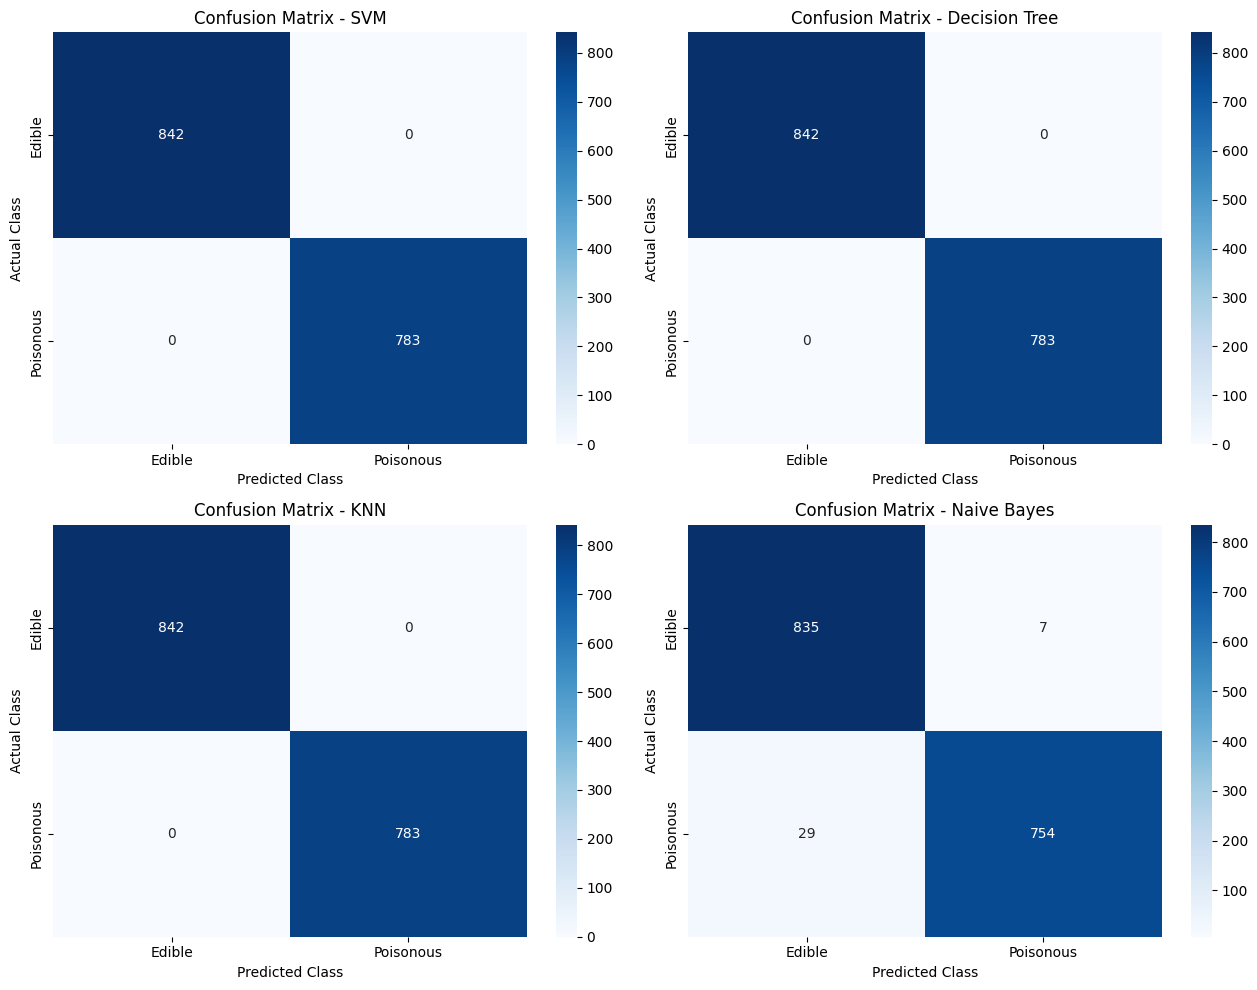

In [18]:

# ==========================================
#  CONFUSION MATRICES
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for ax, (name, y_pred) in zip(
    axes.flatten(), predictions.items()
):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=['e', 'p']
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Edible', 'Poisonous'],
        yticklabels=['Edible', 'Poisonous'],
        ax=ax
    )

    ax.set_title(f'Confusion Matrix - {name}')
    ax.set_xlabel('Predicted Class')
    ax.set_ylabel('Actual Class')

plt.tight_layout()
plt.show()


,Model,Best CV Macro F1,Test Macro F1
0,SVM,1.0000,1.0000
1,Decision Tree,0.9997,1.0000
2,KNN,1.0000,1.0000
3,Naive Bayes,0.9750,0.9778


<Figure size 1000x500 with 0 Axes>

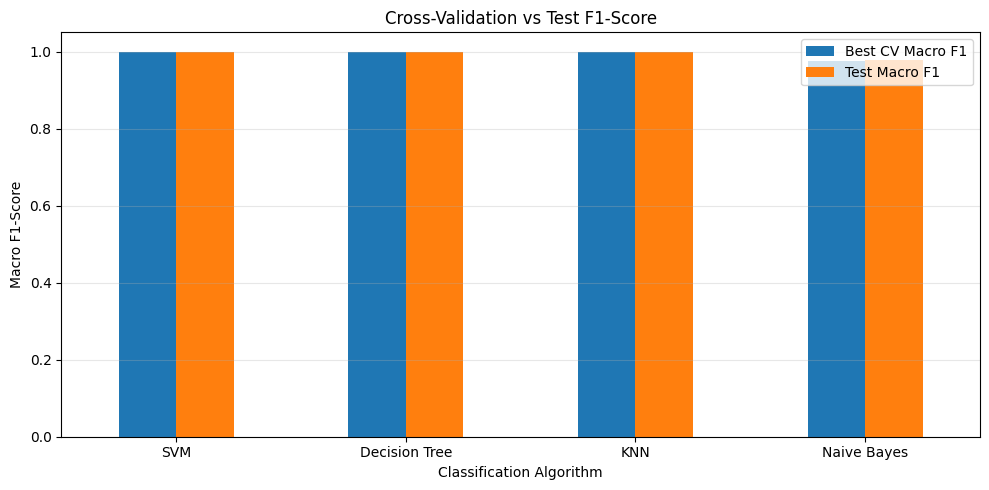

In [19]:

# ==========================================
#  CROSS-VALIDATION COMPARISON
# ==========================================

cv_results = []

for name, search in search_results.items():

    cv_results.append({
        'Model': name,
        'Best CV Macro F1': search.best_score_,
        'Test Macro F1': results_df.loc[
            results_df['Model'] == name,
            'F1-Score (Macro)'
        ].iloc[0]
    })

cv_df = pd.DataFrame(cv_results)

display(cv_df.round(4))

plt.figure(figsize=(10, 5))

cv_df.set_index('Model').plot(
    kind='bar',
    figsize=(10, 5),
    rot=0
)

plt.title('Cross-Validation vs Test F1-Score')
plt.ylabel('Macro F1-Score')
plt.xlabel('Classification Algorithm')
plt.ylim(0, 1.05)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


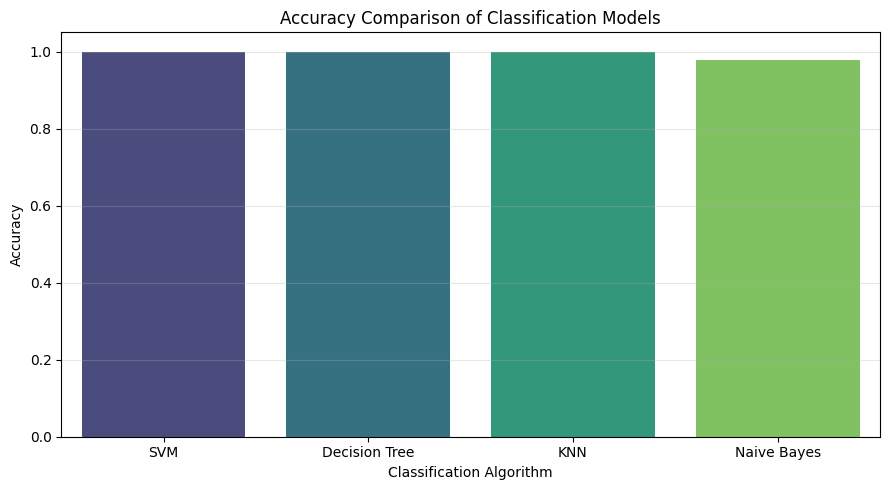

In [20]:

# ==========================================
#  ACCURACY COMPARISON
# ==========================================

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='Accuracy',
    hue='Model',
    palette='viridis',
    legend=False
)

plt.title('Accuracy Comparison of Classification Models')
plt.xlabel('Classification Algorithm')
plt.ylabel('Accuracy')
plt.ylim(0, 1.05)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


**Observation:** The graph compares the overall classification accuracy of the four algorithms. The highest bar represents the model with the highest accuracy on the test dataset.

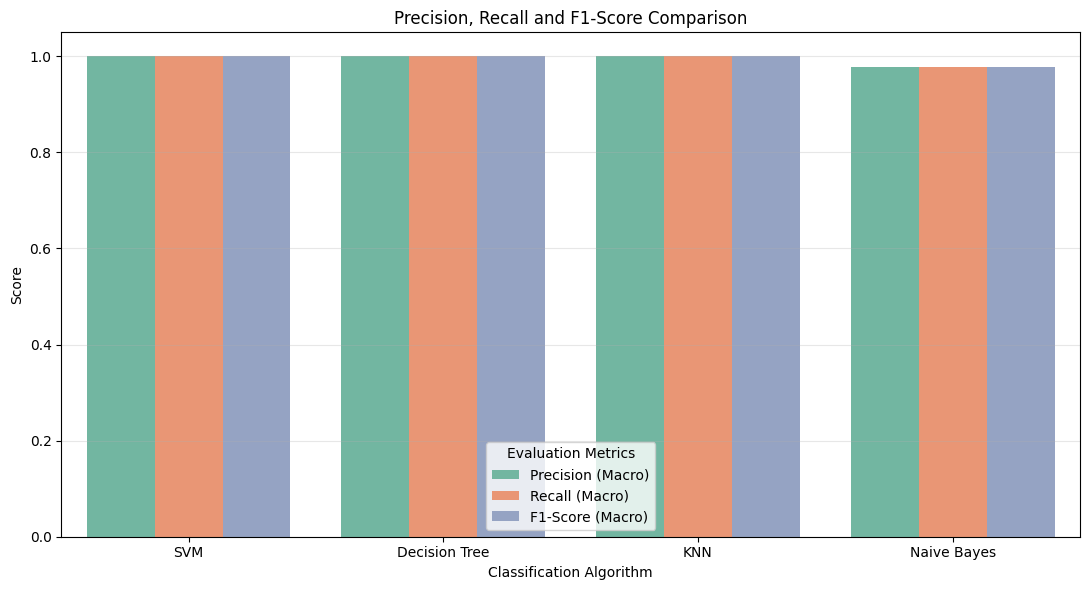

In [21]:

# ==========================================
#  PRECISION, RECALL AND F1 COMPARISON
# ==========================================

metric_columns = [
    'Precision (Macro)',
    'Recall (Macro)',
    'F1-Score (Macro)'
]

metric_data = results_df[
    ['Model'] + metric_columns
].melt(
    id_vars='Model',
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=metric_data,
    x='Model',
    y='Score',
    hue='Metric',
    palette='Set2'
)

plt.title('Precision, Recall and F1-Score Comparison')
plt.xlabel('Classification Algorithm')
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.legend(title='Evaluation Metrics')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


**Observation:** This graph helps determine whether a model performs consistently across precision, recall and F1-score.

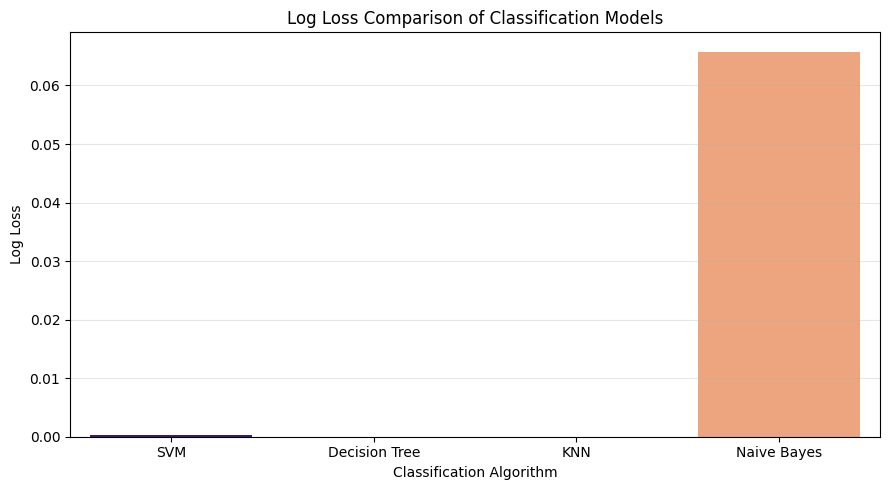

In [22]:

# ==========================================
#  LOG LOSS COMPARISON
# ==========================================

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='Log Loss',
    hue='Model',
    palette='magma',
    legend=False
)

plt.title('Log Loss Comparison of Classification Models')
plt.xlabel('Classification Algorithm')
plt.ylabel('Log Loss')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


**Observation**: A model with lower log loss provides better probability estimates. A model with high accuracy may still have relatively high log loss if its probability estimates are poorly calibrated.

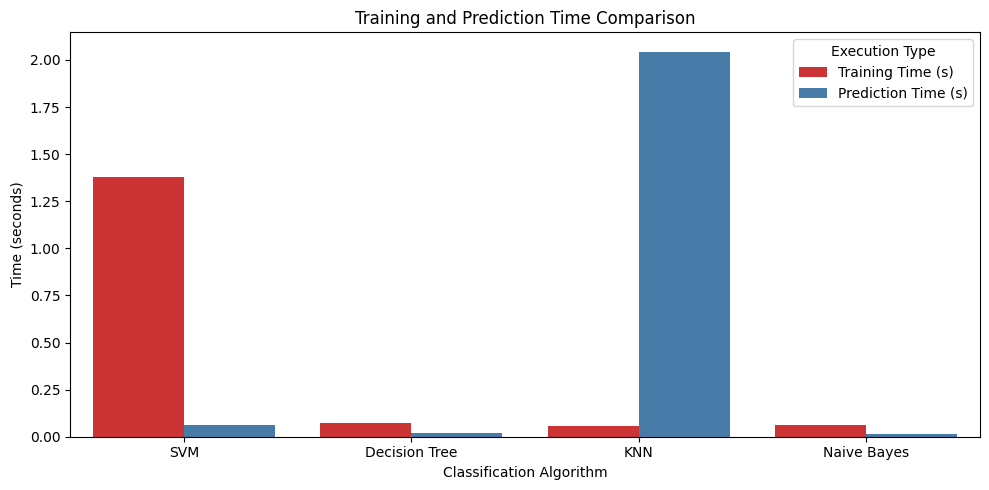

In [23]:

# ==========================================
#  EXECUTION TIME COMPARISON
# ==========================================

time_data = results_df[
    ['Model', 'Training Time (s)', 'Prediction Time (s)']
].melt(
    id_vars='Model',
    var_name='Execution Type',
    value_name='Time (seconds)'
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=time_data,
    x='Model',
    y='Time (seconds)',
    hue='Execution Type',
    palette='Set1'
)

plt.title('Training and Prediction Time Comparison')
plt.xlabel('Classification Algorithm')
plt.ylabel('Time (seconds)')
plt.legend(title='Execution Type')

plt.tight_layout()
plt.show()


**Observation:** This graph helps compare computational efficiency. KNN generally has relatively low training cost because it stores training observations, but prediction can be more computationally expensive.

Top 15 Important Features:


,Feature,Importance
27,categorical__odor_n,0.617790
51,categorical__stalk-root_b,0.182243
35,categorical__gill-size_b,0.087261
99,categorical__spore-print-color_r,0.035830
22,categorical__odor_a,0.022530
25,categorical__odor_l,0.021906
26,categorical__odor_m,0.015878
62,categorical__stalk-surface-below-ring_y,0.013490
7,categorical__cap-surface_g,0.001844
1,categorical__cap-shape_c,0.000616


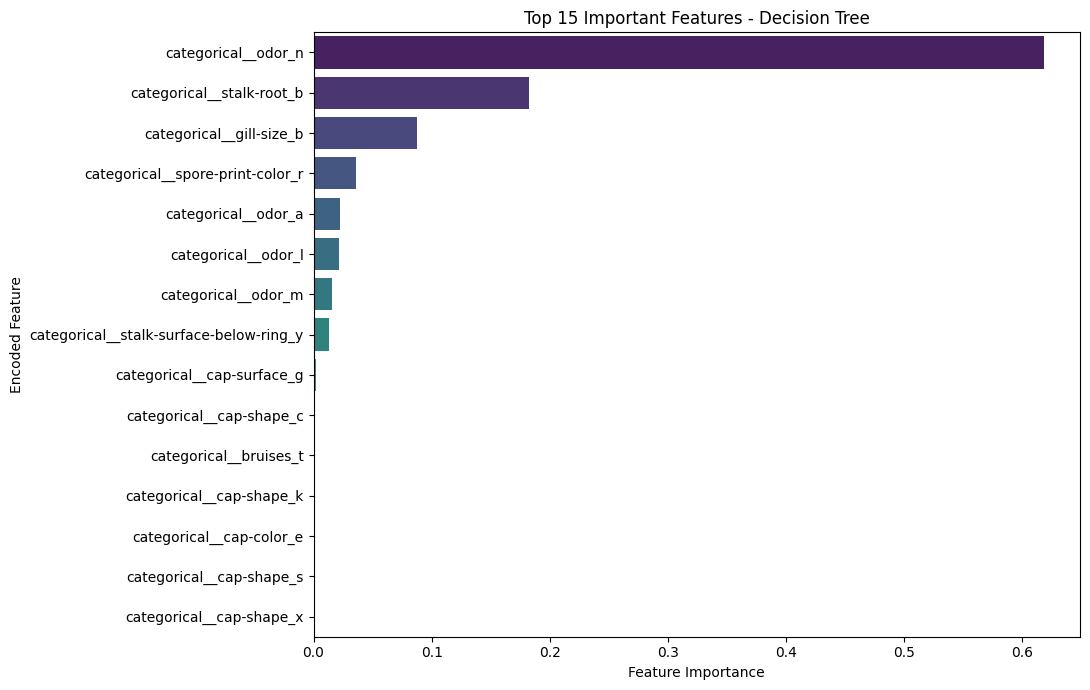

In [24]:

# ==========================================
#  FEATURE IMPORTANCE
# ==========================================

tree_model = best_models['Decision Tree']

# Obtain encoded feature names
feature_names = (
    tree_model
    .named_steps['preprocessor']
    .get_feature_names_out()
)

# Extract feature importance
importances = (
    tree_model
    .named_steps['classifier']
    .feature_importances_
)

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
).head(15)

print("Top 15 Important Features:")
display(importance_df)

plt.figure(figsize=(11, 7))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature',
    hue='Feature',
    palette='viridis',
    legend=False
)

plt.title('Top 15 Important Features - Decision Tree')
plt.xlabel('Feature Importance')
plt.ylabel('Encoded Feature')

plt.tight_layout()
plt.show()


**Analysis:** Feature importance indicates which encoded characteristics the selected Decision Tree relies on most when making predictions. These importance values describe the tree's decision process, not necessarily causal relationships.

In [25]:

# ==========================================
#  MODEL RANKING
# ==========================================

ranked_results = results_df.sort_values(
    by='F1-Score (Macro)',
    ascending=False
).reset_index(drop=True)

print("FINAL MODEL RANKING")
print("=" * 50)

for index, row in ranked_results.iterrows():

    print(
        f"{index + 1}. {row['Model']} "
        f"| Accuracy: {row['Accuracy']:.4f} "
        f"| F1-Score: {row['F1-Score (Macro)']:.4f} "
        f"| Log Loss: {row['Log Loss']:.4f}"
    )

best_model_name = ranked_results.iloc[0]['Model']

print("\nBest Model Based on Macro F1-Score:")
print(best_model_name)

print(
    "Best Test F1-Score:",
    round(ranked_results.iloc[0]['F1-Score (Macro)'], 4)
)


FINAL MODEL RANKING
1. SVM | Accuracy: 1.0000 | F1-Score: 1.0000 | Log Loss: 0.0003
2. Decision Tree | Accuracy: 1.0000 | F1-Score: 1.0000 | Log Loss: 0.0000
3. KNN | Accuracy: 1.0000 | F1-Score: 1.0000 | Log Loss: 0.0000
4. Naive Bayes | Accuracy: 0.9778 | F1-Score: 0.9778 | Log Loss: 0.0658

Best Model Based on Macro F1-Score:
SVM
Best Test F1-Score: 1.0


In [26]:

# ==========================================
#  AUTOMATIC COMPARATIVE FINDINGS
# ==========================================

best_accuracy_model = results_df.loc[
    results_df['Accuracy'].idxmax(), 'Model'
]

best_precision_model = results_df.loc[
    results_df['Precision (Macro)'].idxmax(), 'Model'
]

best_recall_model = results_df.loc[
    results_df['Recall (Macro)'].idxmax(), 'Model'
]

best_f1_model = results_df.loc[
    results_df['F1-Score (Macro)'].idxmax(), 'Model'
]

best_loss_model = results_df.loc[
    results_df['Log Loss'].idxmin(), 'Model'
]

best_safety_model = results_df.loc[
    results_df['Poisonous Recall'].idxmax(), 'Model'
]

print("COMPARATIVE ANALYSIS")
print("=" * 55)

print("Highest Accuracy:", best_accuracy_model)
print("Highest Macro Precision:", best_precision_model)
print("Highest Macro Recall:", best_recall_model)
print("Highest Macro F1-Score:", best_f1_model)
print("Lowest Log Loss:", best_loss_model)
print("Highest Poisonous-Class Recall:", best_safety_model)

print("\nRecommended Overall Model:", best_f1_model)

print("\nReason:")
print(
    "This model achieved the highest macro F1-score "
    "among the four evaluated algorithms on the test dataset."
)


COMPARATIVE ANALYSIS
Highest Accuracy: SVM
Highest Macro Precision: SVM
Highest Macro Recall: SVM
Highest Macro F1-Score: SVM
Lowest Log Loss: Decision Tree
Highest Poisonous-Class Recall: SVM

Recommended Overall Model: SVM

Reason:
This model achieved the highest macro F1-score among the four evaluated algorithms on the test dataset.


## **6. Comparative Analysis of Classification Algorithms**

### **6.1 Support Vector Machine (SVM)**

SVM is suitable for high-dimensional classification problems and can handle complex class boundaries using kernel functions. It is useful when accurate separation between classes is important. However, its computational requirements and limited interpretability can be disadvantages.

###**6.2 Decision Tree**

Decision Tree is suitable for applications where interpretability and explainability are important. It can identify useful feature combinations and represent decisions in a tree structure. However, excessive tree depth may lead to overfitting.

### **6.3 K-Nearest Neighbors (KNN)**

KNN is suitable for problems where similar observations are expected to belong to similar classes. It is useful for local pattern recognition and relatively simple classification tasks. However, its prediction time and sensitivity to distance calculations can be limitations.

### **6.4 Naïve Bayes**

Naïve Bayes is suitable for fast probabilistic classification, especially when the feature representation is compatible with its probability assumptions. It is useful for text classification, document categorization and categorical-data classification. However, its conditional independence assumption may limit its performance when features are strongly related.

### **6.5 Overall Comparison**

| Algorithm | Main Strength | Main Limitation | Suitable Applications |
|---|---|---|---|
| SVM | Effective decision boundaries | Computational cost | High-dimensional classification |
| Decision Tree | Interpretability | Overfitting | Rule-based decision systems |
| KNN | Similarity-based learning | Slow prediction | Recommendation and pattern recognition |
| Naïve Bayes | Fast probability estimation | Independence assumption | Text and document classification |

The actual suitability of each model should be determined using its measured performance, computational requirements and application-specific requirements rather than accuracy alone.

In [27]:

# ==========================================
# EXPERIMENTAL DISCUSSION
# ==========================================

print("EXPERIMENTAL FINDINGS")
print("=" * 60)

for _, row in ranked_results.iterrows():

    print(f"\n{row['Model']}:")

    print(
        f"Accuracy: {row['Accuracy']:.4f}, "
        f"Precision: {row['Precision (Macro)']:.4f}, "
        f"Recall: {row['Recall (Macro)']:.4f}, "
        f"F1-Score: {row['F1-Score (Macro)']:.4f}"
    )

    print(f"Log Loss: {row['Log Loss']:.4f}")

print("\n" + "=" * 60)

print(
    f"Overall best model based on macro F1-score: "
    f"{best_f1_model}"
)

print(
    f"Best model for poisonous-class recall: "
    f"{best_safety_model}"
)

print(
    f"Best model based on probability loss: "
    f"{best_loss_model}"
)


EXPERIMENTAL FINDINGS

SVM:
Accuracy: 1.0000, Precision: 1.0000, Recall: 1.0000, F1-Score: 1.0000
Log Loss: 0.0003

Decision Tree:
Accuracy: 1.0000, Precision: 1.0000, Recall: 1.0000, F1-Score: 1.0000
Log Loss: 0.0000

KNN:
Accuracy: 1.0000, Precision: 1.0000, Recall: 1.0000, F1-Score: 1.0000
Log Loss: 0.0000

Naive Bayes:
Accuracy: 0.9778, Precision: 0.9786, Recall: 0.9773, F1-Score: 0.9778
Log Loss: 0.0658

Overall best model based on macro F1-score: SVM
Best model for poisonous-class recall: SVM
Best model based on probability loss: Decision Tree


## **7. Limitations and Ethical Considerations**

### **7.1 Limitations**

1. The dataset contains categorical features, requiring preprocessing before model training.
2. Some feature values are missing or represented by unknown symbols.
3. The experiment uses one dataset and one stratified train-test split, so the results may vary with different datasets or data distributions.
4. KNN may face computational challenges when the dataset size and feature dimensions increase.
5. Decision Trees may overfit if their complexity is not controlled.
6. Naïve Bayes relies on a conditional independence assumption that may not fully represent relationships between mushroom characteristics.
7. The results depend on the quality and representativeness of the available dataset.

### **7.2 Ethical Considerations**

Classification errors in mushroom identification can have serious safety implications.

A poisonous mushroom incorrectly classified as edible could lead to harmful consequences. Therefore, poisonous-class recall and false-negative predictions deserve particular attention.

The dataset is used strictly for academic and experimental purposes. The trained models should not be used as substitutes for expert mushroom identification or food-safety verification.

### **7.3 Future Improvements**

1. Evaluate the models using additional mushroom datasets.
2. Explore more advanced hyperparameter optimization techniques.
3. Apply ensemble learning methods such as Random Forest and Gradient Boosting.
4. Perform feature selection to reduce unnecessary input dimensions.
5. Evaluate model calibration and reliability of predicted probabilities.
6. Test model performance on independent external datasets.

## **8. Conclusion**

In this experiment, four classification algorithms — Support Vector Machine (SVM), Decision Tree, K-Nearest Neighbors (KNN), and Naïve Bayes — were implemented and evaluated using the Mushroom Classification dataset to predict whether mushrooms are edible or poisonous.

The dataset was preprocessed using missing-value handling and one-hot encoding to convert categorical features into a suitable numerical format. The models were trained and evaluated using accuracy, precision, recall, F1-score, and log loss.

The results showed that **SVM, Decision Tree, and KNN achieved 100% accuracy**, with perfect precision, recall, and F1-score on the test dataset. Naïve Bayes achieved an accuracy of **97.78%**, showing good performance but slightly lower results than the other three models. The log-loss values also indicated that the models provided highly confident predictions.

Overall, SVM, Decision Tree, and KNN performed exceptionally well on this dataset, while Naïve Bayes also demonstrated strong classification ability. This experiment highlights that model performance depends on the characteristics of the dataset and that multiple evaluation metrics are important when selecting a suitable classification algorithm.

## **9. Learning Outcomes and Reflection**

After completing this experiment, I was able to:

1. Understand the working principles of supervised classification algorithms such as SVM, Decision Tree, KNN, and Naïve Bayes.
2. Perform data preprocessing, including handling missing values and encoding categorical features.
3. Split a dataset into training and testing sets and train multiple classification models.
4. Evaluate model performance using accuracy, precision, recall, F1-score, and log loss.
5. Understand and compare confusion matrices and classification reports.
6. Apply hyperparameter tuning using GridSearchCV to improve model performance.
7. Visualize and interpret the performance of different classification algorithms.
8. Identify the strengths and limitations of different classifiers and understand their suitability for classification problems.

In [31]:

# ==========================================
# FINAL COMPARISON TABLE
# ==========================================

final_comparison = results_df[
    [
        'Model',
        'Accuracy',
        'Precision (Macro)',
        'Recall (Macro)',
        'F1-Score (Macro)',
        'Log Loss',
        'Poisonous Recall'
    ]
].copy()

final_comparison = final_comparison.round(4)

print("FINAL COMPARATIVE ANALYSIS TABLE")

display(final_comparison)

# Identify the best model
best_model = final_comparison.iloc[0]

print("\nBEST OVERALL MODEL")
print("------------------------------")
print("Algorithm:", best_model['Model'])
print("Accuracy:", best_model['Accuracy'])
print("Macro Precision:", best_model['Precision (Macro)'])
print("Macro Recall:", best_model['Recall (Macro)'])
print("Macro F1-Score:", best_model['F1-Score (Macro)'])
print("Log Loss:", best_model['Log Loss'])
print("Poisonous Recall:", best_model['Poisonous Recall'])


FINAL COMPARATIVE ANALYSIS TABLE


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),Log Loss,Poisonous Recall
0,SVM,1.0000,1.0000,1.0000,1.0000,0.0003,1.000
1,Decision Tree,1.0000,1.0000,1.0000,1.0000,0.0000,1.000
2,KNN,1.0000,1.0000,1.0000,1.0000,0.0000,1.000
3,Naive Bayes,0.9778,0.9786,0.9773,0.9778,0.0658,0.963



BEST OVERALL MODEL
------------------------------
Algorithm: SVM
Accuracy: 1.0
Macro Precision: 1.0
Macro Recall: 1.0
Macro F1-Score: 1.0
Log Loss: 0.0003
Poisonous Recall: 1.0


In [29]:

# ==========================================
# EXPORT MODEL RESULTS
# ==========================================

results_df.to_csv(
    'Mushroom_Classification_Results.csv',
    index=False
)

print("Results exported successfully!")

from google.colab import files

files.download('Mushroom_Classification_Results.csv')


Results exported successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>